In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from numpy.polynomial import Polynomial
import kagglehub

# Set the plot style
sns.set_theme(style='ticks')

# Load the student performance dataset
path = kagglehub.dataset_download("nikhil7280/student-performance-multiple-linear-regression")

df = pd.read_csv(path + "/Student_Performance.csv")

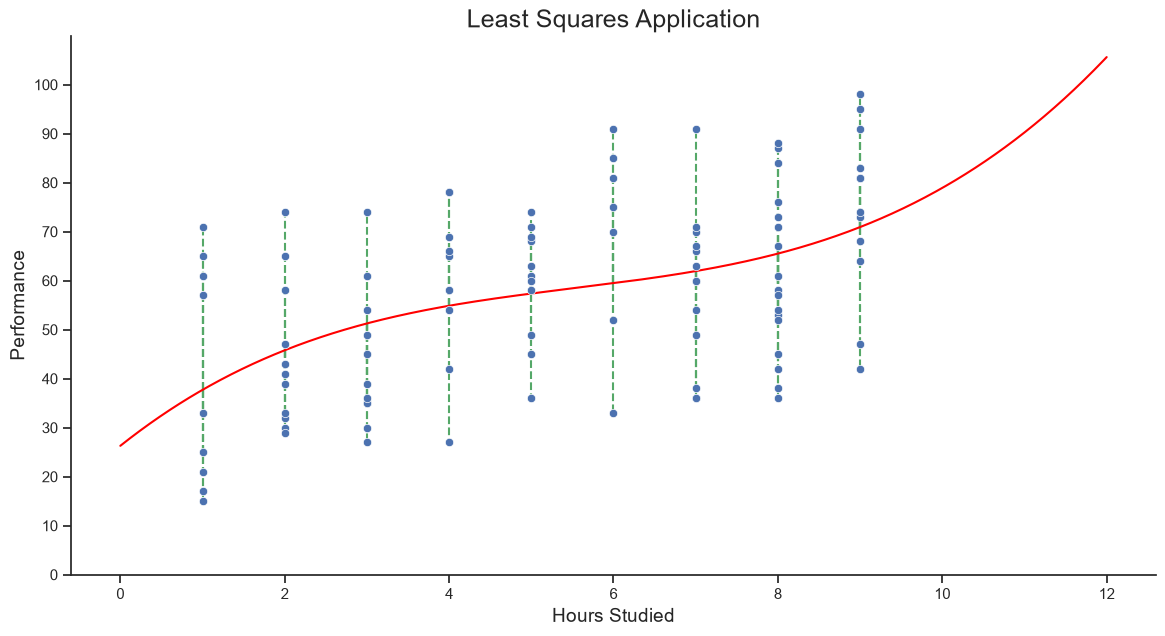

In [17]:
# Use a small subset to make the fitted curve and residuals easier to visualize
df_plot = df.loc[:99, ['Hours Studied', 'Performance Index']]

# Fit a nth-degree polynomial by minimizing the sum of squared residuals
deg = 3

p = Polynomial.fit(df_plot['Hours Studied'], df_plot['Performance Index'], deg)

# Generate points along the fitted curve to obtain a smooth visualization
x = np.linspace(0, 12, 1000)

y = p(x)

data = pd.DataFrame({'x':x,'y':y})

plt.figure(figsize=(14, 7))

# Plot the model's predictions
sns.lineplot(data, x=x, y=y, color='red', zorder=3)

# Plot the actual observations to compare them with the model's predictions
sns.scatterplot(df_plot,  x='Hours Studied', y='Performance Index', zorder=3)

# Visualize the residual of each observation as a vertical distance
# Least squares minimizes the sum of the squares of these residuals
for Houres,Performance in df_plot.itertuples(index=False):
    plt.plot([Houres, Houres], [p(Houres), Performance], 'g--')

sns.despine()

# Set the visible range and tick intervals for the performance axis
plt.ylim(0, 110)
plt.yticks(np.arange(0, 101, 10))

plt.ylabel('Performance', fontsize=14)
plt.xlabel('Hours Studied',fontsize=14)
plt.title('Least Squares Application', fontsize=18)

plt.show()